# County Exploratory Analysis


This notebook is our **purposeful exploratory evidence**: figures and a summary table that address the project's supporting questions about wildfire, income, and California FAIR Plan adoption. It expands the ZIP-level preliminary analysis (`scripts/old/Preliminary_Exploratory_Analysis.ipynb`) to the county level, which the team now uses.



**Steps**
1. Set up the Python session
2. Load the processed data
3. Build the county table
4. Figures and summary table answering the supporting questions

---
### 1. Set up your Python session

#### 1.1 Import packages

In [1]:
# Import packages
from pathlib import Path
import pandas as pd
import seaborn as sns

#### 1.2 Set project folder paths

In [2]:
# file path to import data
root_fldr = Path.cwd().parent
raw_fldr = root_fldr / 'data' / 'raw'
processed_fldr = root_fldr / 'data' / 'processed'

---
### 2. Load the processed data

In [3]:
# Import the processed county income and fire data 2022-24
county_income = pd.read_csv(
    processed_fldr/'County_Income_CFP_2022_2024.csv',
    dtype={'GEOID': 'str'},
    )

county_fire = pd.read_csv(
    processed_fldr/'fire_by_county_2022_2024.csv',
    )
county_fire = county_fire.drop(columns=['Unnamed: 0', 'geometry'])

print('County income:', county_income.shape)
print('County fire:', county_fire.shape)

County income: (174, 7)
County fire: (1169, 9)


---
### 3. Build the county table
The figures and summary table compare counties, so this section builds one table with **one row per county**: FAIR Plan policies in 2022 and 2024, the growth between them, and median household income in 2022.

#### 3.1 Spread policies into one column per year
* Reshape `county_income` so each year's policies sit in their own column (`2022`, `2023`, `2024`).
* Reset the index so `county` is a normal column again.

In [4]:
# Spread policies so each year has its own column
policies_wide = (
    county_income
    .pivot_table(
        index=['county'],
        columns='year',
        values='policies'
    )
    .reset_index()
)
policies_wide.columns.name = None
policies_wide.head()

,county,2022,2023,2024
0,Alameda,2956.0,3519.0,6774.0
1,Alpine,263.0,297.0,346.0
2,Amador,4041.0,4742.0,5495.0
3,Butte,3722.0,5878.0,8165.0
4,Calaveras,6983.0,8520.0,9548.0


#### 3.2 Add policy growth from 2022 to 2024
* Growth (%) = (policies in 2024 ÷ policies in 2022 − 1) × 100
* The denominator is each county's own 2022 policies, so large and small counties can be compared.

In [5]:
# Add policy growth from 2022 to 2024 (%)
county_growth = (
    policies_wide
    .assign(
            policy_growth_pct = lambda df: (df[2024] / df[2022] - 1) * 100,
    )
)

county_growth.head()

,county,2022,2023,2024,policy_growth_pct
0,Alameda,2956.0,3519.0,6774.0,129.161028
1,Alpine,263.0,297.0,346.0,31.558935
2,Amador,4041.0,4742.0,5495.0,35.981193
3,Butte,3722.0,5878.0,8165.0,119.371306
4,Calaveras,6983.0,8520.0,9548.0,36.732064


#### 3.3 Keep each county's 2022 income
* Keep only the 2022 rows, and only the `county` and `Median_income` columns.
* 2022 is the first year of the growth period, so this is each county's income at the start.

In [6]:
# Keep each county's 2022 income
income_2022 = county_income.query('year == 2022')
income_2022 = income_2022[['county', 'Median_income']]
income_2022.head()

,county,Median_income
0,Alameda,122488
1,Alpine,101125
2,Amador,74853
3,Butte,66085
4,Calaveras,77526


#### 3.4 Join income onto the growth table
* Left join on `county`, keeping all 58 counties.
* Check the result: it should still have 58 rows, with no county missing income.

In [7]:
# Left join: keep all counties in county_growth and add their 2022 income
county_table = pd.merge(
    county_growth,
    income_2022,
    on='county',
    how='left'
)

print(county_table.shape)
print('Counties missing income:', county_table['Median_income'].isna().sum())
county_table.head()

(58, 6)
Counties missing income: 0


,county,2022,2023,2024,policy_growth_pct,Median_income
0,Alameda,2956.0,3519.0,6774.0,129.161028,122488
1,Alpine,263.0,297.0,346.0,31.558935,101125
2,Amador,4041.0,4742.0,5495.0,35.981193,74853
3,Butte,3722.0,5878.0,8165.0,119.371306,66085
4,Calaveras,6983.0,8520.0,9548.0,36.732064,77526


### 4. Data Visualization

#### 4.1 Plot 2022 median income against policy growth
* One dot per county (58).
* x = median household income in 2022, y = growth in FAIR Plan policies from 2022 to 2024 (%).

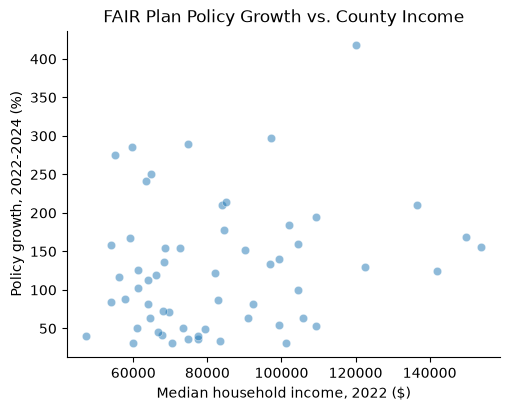

In [8]:
# 4.1 Create a scatterplot of median income vs policy growth
g = sns.relplot(
    data=county_table,
    x='Median_income', 
    y='policy_growth_pct',  
    alpha=0.5,
    height=4,
    aspect=1.3,
).set(
    title  = 'FAIR Plan Policy Growth vs. County Income',
    xlabel = 'Median household income, 2022 ($)',
    ylabel = 'Policy growth, 2022-2024 (%)',
 );



####  4.2 Add total acres burned to the county table
* Add up `acres_burned` for each county over 2022–2024 (the fire table has one row per fire per county).
* Make the county names match: the fire table says `Butte County`, the county table says `Butte`.
* Join onto `county_table` and set counties with no fire to 0.


In [9]:
# 4.2.1 Add up acres burned for each county, 2022-2024
fire_totals = (
    county_fire
    .groupby('county_name', as_index=False)
    .agg(acres_burned_total=('acres_burned', 'sum'))
)

# Remove ' County' so names match county_table ('Butte County' -> 'Butte')
fire_totals['county'] = fire_totals['county_name'].str.replace(' County', '')
fire_totals = fire_totals[['county', 'acres_burned_total']]
fire_totals.head()


,county,acres_burned_total
0,Alameda,2365.123992
1,Alpine,32.593858
2,Amador,2828.727542
3,Butte,60036.571649
4,Calaveras,7390.358190


In [10]:
# 4.2.2 Left join: keep all 58 counties and add their acres burned
county_table = pd.merge(
    county_table,
    fire_totals,
    on='county',
    how='left'
)

print('Counties with no fire:', county_table['acres_burned_total'].isna().sum())

# Counties with no fire get 0 acres instead of NaN
county_table['acres_burned_total'] = county_table['acres_burned_total'].fillna(0)
print(county_table.shape)
county_table.head()


Counties with no fire: 5
(58, 7)


,county,2022,2023,2024,policy_growth_pct,Median_income,acres_burned_total
0,Alameda,2956.0,3519.0,6774.0,129.161028,122488,2365.123992
1,Alpine,263.0,297.0,346.0,31.558935,101125,32.593858
2,Amador,4041.0,4742.0,5495.0,35.981193,74853,2828.727542
3,Butte,3722.0,5878.0,8165.0,119.371306,66085,60036.571649
4,Calaveras,6983.0,8520.0,9548.0,36.732064,77526,7390.358190


#### 4.3 Plot acres burned against policy growth
* One dot per county that had a fire in 2022–2024 (53 counties).
* x = total acres burned 2022–2024 on a log scale, y = growth in FAIR Plan policies from 2022 to 2024 (%).
* The 5 counties with no fire are left out, because a log scale can't show 0.


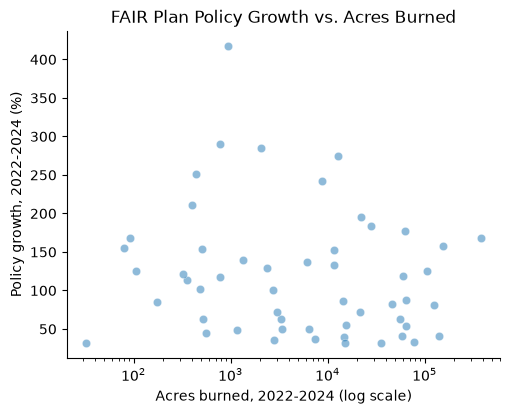

In [11]:
# 4.3 Create a scatterplot of acres burned vs policy growth
burned_counties = county_table.query('acres_burned_total > 0')

g = sns.relplot(
    data=burned_counties,
    x='acres_burned_total',
    y='policy_growth_pct',
    alpha=0.5,
    height=4,
    aspect=1.3,
).set(
    title  = 'FAIR Plan Policy Growth vs. Acres Burned',
    xlabel = 'Acres burned, 2022-2024 (log scale)',
    ylabel = 'Policy growth, 2022-2024 (%)',
    xscale = 'log',
 );


#### 4.4 Summary table by income group
* Split the 58 counties into three equal-sized groups by 2022 median income.
* For each group, report: number of counties, income range, total policies in 2022 and 2024, median policy growth (%), and total acres burned 2022–2024.


In [12]:
# 4.4.1 Split counties into three income groups
county_table['income_group'] = pd.qcut(
    county_table['Median_income'],
    q=3,
    labels=['Lower income', 'Middle income', 'Higher income']
)
county_table[['county', 'Median_income', 'income_group']].head()


,county,Median_income,income_group
0,Alameda,122488,Higher income
1,Alpine,101125,Higher income
2,Amador,74853,Middle income
3,Butte,66085,Lower income
4,Calaveras,77526,Middle income


In [13]:
# 4.4.2 Summarize policies, growth and fire by income group
income_summary = (
    county_table
    .groupby('income_group', observed=True)
    .agg(
        counties=('county', 'count'),
        income_min=('Median_income', 'min'),
        income_max=('Median_income', 'max'),
        policies_2022=(2022, 'sum'),
        policies_2024=(2024, 'sum'),
        median_growth_pct=('policy_growth_pct', 'median'),
        total_acres_burned=('acres_burned_total', 'sum'),
    )
    .round(1)
    .reset_index()
)
income_summary


,income_group,counties,income_min,income_max,policies_2022,policies_2024,median_growth_pct,total_acres_burned
0,Lower income,20,47317,67756,25290.0,46986.0,107.8,1080358.4
1,Middle income,19,67885,90158,177241.0,265581.0,86.6,372428.9
2,Higher income,19,91043,153792,70815.0,150591.0,133.5,200604.9


#### 4.5 Policy trend by income group
* Add up policies in each income group for 2022, 2023 and 2024.
* Index each group to its own 2022 total (2022 = 100), so groups of different sizes can be compared.
* Plot one line per income group.

In [14]:
# 4.5.1 Total policies per income group, indexed to 2022 = 100
group_policies = (
    county_table
    .groupby('income_group', observed=True)[[2022, 2023, 2024]]
    .sum()
    .reset_index()
)

group_index = group_policies.copy()
for year in [2022, 2023, 2024]:
    group_index[year] = group_policies[year] / group_policies[2022] * 100

group_index

,income_group,2022,2023,2024
0,Lower income,100.0,130.640569,185.788849
1,Middle income,100.0,115.736201,149.841741
2,Higher income,100.0,130.048718,212.654099


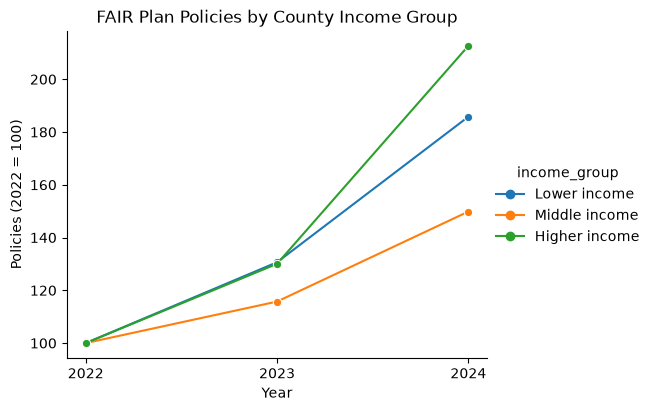

In [15]:
# 4.5.2 Reshape to long form and plot one line per income group
group_trend = group_index.melt(
    id_vars='income_group',
    var_name='year',
    value_name='policies_index'
)
group_trend['year'] = group_trend['year'].astype(int)

g = sns.relplot(
    data=group_trend,
    x='year',
    y='policies_index',
    hue='income_group',
    kind='line',
    marker='o',
    height=4,
    aspect=1.3,
).set(
    title  = 'FAIR Plan Policies by County Income Group',
    xlabel = 'Year',
    ylabel = 'Policies (2022 = 100)',
    xticks = [2022, 2023, 2024],
 );


---
### 5. Save the county table
#### 5.1 Save the county table to the processed folder
* Rename the year columns so the file is clear in both Python and R (`2022` → `policies_2022`).
* Save it as `County_Income_CFP_Fire_2022_2024.csv` without the index.


In [16]:
# 5.1 Save the county table
county_table_export = county_table.rename(columns={
    2022: 'policies_2022',
    2023: 'policies_2023',
    2024: 'policies_2024',
})

county_table_export.to_csv(
    processed_fldr / 'County_Income_CFP_Fire_2022_2024.csv',
    index=False
)
print(county_table_export.shape)
county_table_export.head()


(58, 8)


,county,policies_2022,policies_2023,policies_2024,policy_growth_pct,Median_income,acres_burned_total,income_group
0,Alameda,2956.0,3519.0,6774.0,129.161028,122488,2365.123992,Higher income
1,Alpine,263.0,297.0,346.0,31.558935,101125,32.593858,Higher income
2,Amador,4041.0,4742.0,5495.0,35.981193,74853,2828.727542,Middle income
3,Butte,3722.0,5878.0,8165.0,119.371306,66085,60036.571649,Lower income
4,Calaveras,6983.0,8520.0,9548.0,36.732064,77526,7390.358190,Middle income
